#  Scalar Reverse-Mode Autograd & Higher-Order Derivatives


In **Module 2**, we explored how dynamic computational graphs are assembled during the forward pass. Now, we introduce the algorithmic core of modern deep learning: **Reverse-Mode Automatic Differentiation (Backpropagation)**.

Unlike naive numerical approximations or static symbolic engines, reverse-mode autodiff evaluates exact analytical derivatives by traversing the computational Directed Acyclic Graph (DAG) in **reverse topological order**, applying the multivariate chain rule:

$$\frac{\partial L}{\partial x} = \sum_{y \in \text{children}(x)} \frac{\partial L}{\partial y} \cdot \frac{\partial y}{\partial x}$$

Because `utorch` accumulates gradients as full **`Tensor`** instances (rather than raw detached numbers), the backward pass dynamically constructs a **secondary computational graph**—granting us arbitrary higher-order derivatives ($\frac{d^2 y}{dx^2}$, Hessians) for free!

---

## 🔬 Notebook Roadmap & Experiments

| # | Experiment | Pedagogical Focus | Key Insight |
|:---:|:---|:---|:---|
| **01** | **Scalar Backpropagation & DAG Inspection** | Reverse topological ordering & the chain rule | Seeding $dL/dL = 1.0$ and propagating gradients backwards to leaf inputs. We visualize `x.grad` to inspect the backward computational graph. |
| **02** | **Higher-Order Derivatives (Double Backward)** | Gradients as first-class `Tensor` nodes | Calling `first_grad.backward()` traverses the backward graph to evaluate second-order derivatives ($\frac{d^2 y}{dx^2} = 6x$) without manual Hessian formulas. |
| **03** | **Polynomial Derivative Cascade** ($f(x) = x^4$) | Continuous order reduction | Visualizing how consecutive derivatives decay from a quartic curve down to cubic ($4x^3$) and parabolic ($12x^2$) forms using `plot_function_and_der`. |
| **04** | **Trigonometric Harmonic Cycles** ($f(x) = \sin(x)$) | Cyclic graph derivatives | Visualizing the infinite cycle of trigonometric differentiation: $\sin(x) \to \cos(x) \to -\sin(x) \to -\cos(x)$. |
| **05** | **Neural Activation Gradients** ($f(x) = \sigma(x)$) | Saturation & vanishing gradients | Plotting the bell-shaped derivative $\sigma'(x) = \sigma(x)(1 - \sigma(x))$ to demonstrate why saturated activations impede backpropagation. |
---

In [1]:
from utorch.utils import draw_graph
from utorch import Tensor
import numpy as np
import matplotlib.pyplot as plt
from collections.abc import Callable


In [50]:
x = Tensor(2, name="x")
y = (x ** 2) + 2 * x - 1.0  # dy/dx = 2x + 2
y.backward()
print(x.grad.value)  # 6

6.0


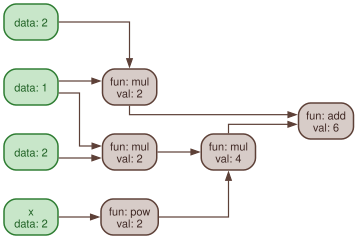

In [51]:
draw_graph(x.grad)

In [52]:
# Let y = x^3.
# First derivative:  dy/dx  = 3x^2 -> at x=2: 3 * 10 = 300
# Second derivative: d2y/dx2 = 6x   -> at x=2: 6 * 10 = 60
x = Tensor(10.0, name="x")
y = x ** 3

# 1. First backward pass
y.backward()
print(f"First derivative (dy/dx) at x=2: {x.grad.value}")

# 2. Reset leaf gradient and backpropagate THROUGH the first gradient!
first_grad = x.grad
x.zero_grad()

first_grad.backward()
print(f"Second derivative (d2y/dx2) at x=2: {x.grad.value}")


First derivative (dy/dx) at x=2: 300.0
Second derivative (d2y/dx2) at x=2: 60.0


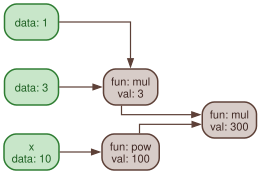

In [53]:
draw_graph(first_grad)

In [59]:
def plot_function_and_der(
    fun: Callable[[Tensor], Tensor],
    x_range: tuple[float, float] = (-2.0, 2.0),
    n_derivatives: int = 2,
    n_points: int = 200,
    title: str | None = None,
) -> None:
    """Plot a function and its first n derivatives computed via autograd.

    Leverages higher-order automatic differentiation: repeatedly calling
    backward() on accumulated Tensor gradients to obtain arbitrary order
    derivatives [f(x), f'(x), f''(x), ..., f^(n)(x)].

    Args:
        fun: Callable taking a Tensor and returning a scalar Tensor.
        x_range: (min_x, max_x) interval for evaluation.
        n_derivatives: Number of consecutive derivatives to compute and plot (e.g. 1, 2, 3).
        n_points: Resolution of the curve grid.
        title: Optional plot title.
    """
    x_points = np.linspace(x_range[0], x_range[1], num=n_points)

    def evaluate_all_orders(x_val: float) -> list[float]:
        # Leaf input node
        x_var = Tensor(x_val)
        y = fun(x_var)

        curves = [float(y.value)]
        current_target = y

        # Repeatedly differentiate through the gradient graph
        for _ in range(n_derivatives):
            x_var.zero_grad()
            current_target.backward()
            current_target = x_var.grad
            curves.append(float(current_target.value))

        return curves

    # Matrix of shape (n_points, 1 + n_derivatives)
    evaluations = np.array([evaluate_all_orders(x) for x in x_points])

    # Distinct line styles and colors
    styles = ["-", "--", "-.", ":", "-"]
    colors = ["#1f77b4", "#ee4c2c", "#2ca02c", "#9467bd", "#ff7f0e"]

    plt.figure(figsize=(9, 5))

    # Plot original function: f(x)
    plt.plot(
        x_points,
        evaluations[:, 0],
        label="$f(x)$",
        color=colors[0],
        linestyle=styles[0],
        linewidth=2.5,
    )

    # Plot each derivative: f'(x), f''(x), f'''(x)...
    labels = ["$f'(x)$", "$f''(x)$", "$f'''(x)$", "$f^{(4)}(x)$"]
    for i in range(1, n_derivatives + 1):
        label = labels[i - 1] if i - 1 < len(labels) else f"$f^{{({i})}}(x)$"
        plt.plot(
            x_points,
            evaluations[:, i],
            label=label,
            color=colors[i % len(colors)],
            linestyle=styles[i % len(styles)],
            linewidth=1.8,
        )

    plt.axhline(0, color="black", linewidth=0.7, linestyle="--", alpha=0.5)
    plt.axvline(0, color="black", linewidth=0.7, linestyle="--", alpha=0.5)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(frameon=True, facecolor="white", framealpha=0.9)
    plt.xlabel("$x$", fontsize=11)
    plt.ylabel("$y$", fontsize=11)
    plt.title(
        title or f"Function and First {n_derivatives} Autograd Derivatives",
        fontsize=12,
        fontweight="bold",
    )
    plt.tight_layout()
    plt.show()


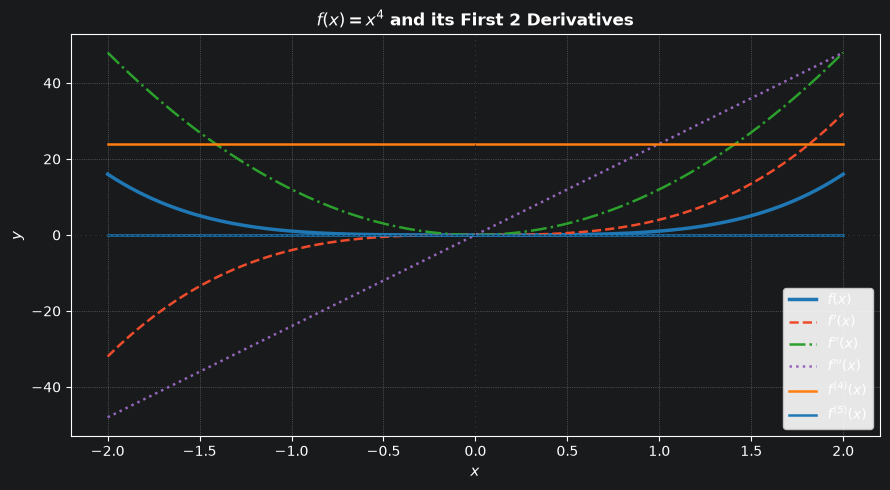

In [55]:
plot_function_and_der(
    fun=lambda x: x ** 4,
    x_range=(-2.0, 2.0),
    n_derivatives=5,
    title="$f(x) = x^4$ and its First 2 Derivatives",
)

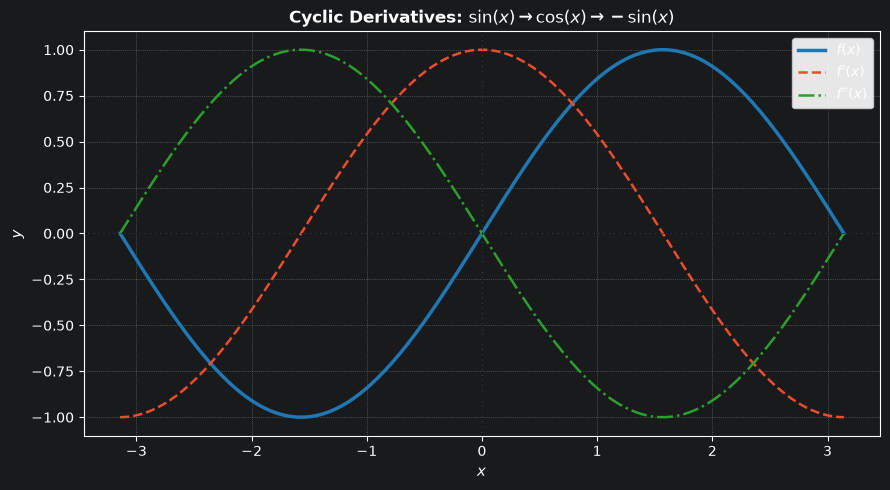

In [42]:
plot_function_and_der(
    fun=lambda x: x.sin(),
    x_range=(-np.pi, np.pi),
    n_derivatives=2,
    title="Cyclic Derivatives: $\\sin(x) \\to \\cos(x) \\to -\\sin(x)$",
)

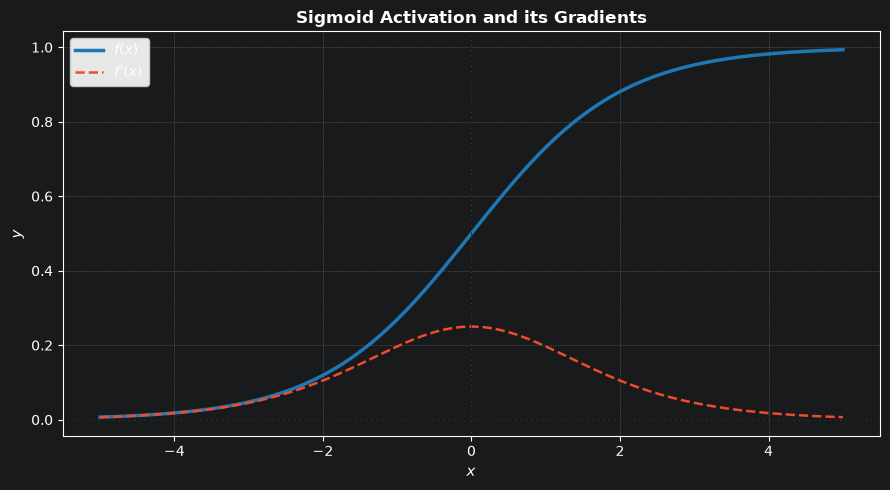

In [56]:
plot_function_and_der(
    fun=lambda x: x.sigmoid(),
    x_range=(-5.0, 5.0),
    n_derivatives=1,
    title="Sigmoid Activation and its Gradients",
)


In [57]:
def fib(n):
    if n <= 1:
        return n
    return fib(n - 1) + fib(n - 2)


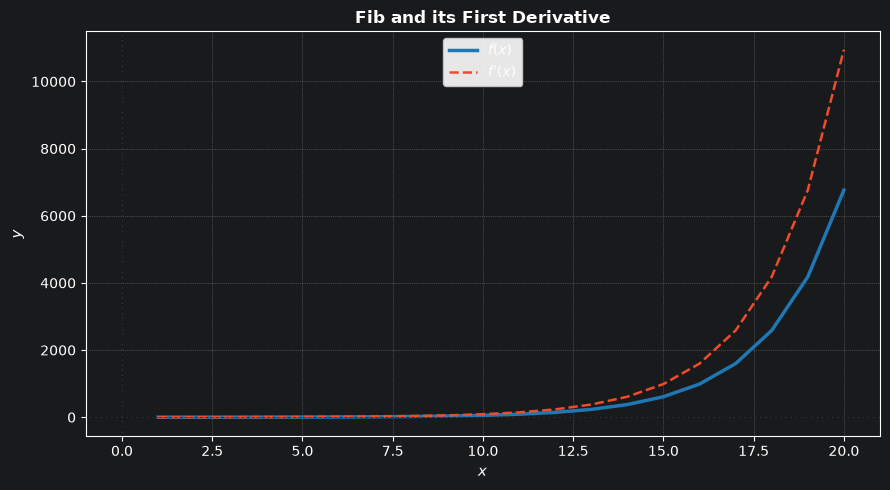

In [58]:
plot_function_and_der(
    fun=lambda x: fib(x),
    x_range=(1, 20),
    n_derivatives=1,
    n_points =20,
    title="Fib and its First Derivative",
)

